# NeuroPipe adaptive framework
NeuroPipe adaptive framework
============================
Pipeline (identical stages to the NeuroPipe technical report, Fig. 2):

  (1) multi-sensor data  ->  (2) pre-processing (detrend / DC removal / band-pass /
  window segmentation / Stationary-Wavelet denoising)  ->  (3) multi-level features
  L0 (5 time-domain) + L1 (8 STFT band energies) + L2 (5 sensor-level) = 18-d
  ->  (4) Time-to-First-Spike (TTFS) encoding  ->  (5) Adaptive-LIF SNN
  (18 -> 64 -> 4), surrogate-gradient training, AdamW, cross-entropy.
  Evaluation: accuracy, precision/recall/F1, confusion matrix, ROC/PR AUC,
  plus synaptic-operation (SOP) and estimated-energy comparison of TTFS vs rate coding.

"Adaptive" = the same code runs on any sensor set through a SensorConfig preset:
  NEXUS_CFG     -> old sewer data (TDS, turbidity, flow @ 1 Hz), usable today
  PNEUMATIC_CFG -> new NeuroPipe testbed (acoustic @ 8 kHz, pressure, vibration, temp, flow)

Dependencies: numpy pandas scipy scikit-learn torch PyWavelets matplotlib

**How to use:** run the cells top to bottom. Set `RAW_DIR` and `CSV_PATH` in the *Experiment settings* cell to your cloned NEXUS repo. The last cells run the full grid (about 10 min on CPU) and print the summary table.

In [1]:
from __future__ import annotations
import json, math, random
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
from scipy import signal, stats
import pywt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, cohen_kappa_score,
                             matthews_corrcoef, precision_recall_fscore_support, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report)
from sklearn.preprocessing import label_binarize

EPS = 1e-9


def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

## 0. Sensor configuration (the "adaptive" part)

In [2]:
# ----------------------------------------------------------------------------------
# 0. Sensor configuration (the "adaptive" part)
# ----------------------------------------------------------------------------------
@dataclass
class SensorConfig:
    name: str
    fs: float                         # sampling rate of the primary (dynamic) channel, Hz
    primary: str                      # channel used for L0 + L1 (acoustic in NeuroPipe)
    channels: list                    # all channel names present in the window dict
    band_edges: list                  # 9 edges -> 8 STFT bands (Hz)
    nperseg: int                      # STFT segment length
    l2: list                          # 5 x (feature_name, channel, statistic)
    bandpass: tuple | None = None     # (low, high) Hz applied to primary channel only
    window_s: float = 30.0            # report: 30 s window
    overlap: float = 0.5              # report: 50 % overlap
    class_names: list = field(default_factory=list)


NEXUS_CFG = SensorConfig(
    name="NEXUS (sewer) mapped onto the NeuroPipe pipeline",
    fs=1.0, primary="Turbidity_raw",
    channels=["TDS_raw", "Turbidity_raw", "Flow_L_min"],
    band_edges=list(np.linspace(0.0, 0.5, 9)), nperseg=16,
    l2=[("tds_mean", "TDS_raw", "mean"), ("turb_mean", "Turbidity_raw", "mean"),
        ("flow_mean", "Flow_L_min", "mean"), ("flow_var", "Flow_L_min", "std"),
        ("tds_transient", "TDS_raw", "max_abs_diff")],
    class_names=["Normal", "Contaminated", "Muddy/partial block", "Severe block"])

PNEUMATIC_CFG = SensorConfig(
    name="NeuroPipe pneumatic leak testbed",
    fs=8000.0, primary="acoustic",
    channels=["acoustic", "pressure", "vibration", "temperature", "flow"],
    band_edges=[100, 300, 600, 900, 1200, 1600, 2000, 3000, 4000], nperseg=256,
    l2=[("pressure_transient", "pressure", "max_abs_diff"), ("vibration_rms", "vibration", "rms"),
        ("temperature", "temperature", "mean"), ("flow_rate", "flow", "mean"),
        ("flow_variation", "flow", "std")],
    bandpass=(100.0, 3000.0),
    class_names=["Normal", "Small leak", "Medium leak", "Large leak"])
# NOTE: in the pneumatic testbed the auxiliary sensors are sampled at ~50 Hz, acoustic at 8 kHz.
# Resample / hold the slow channels to the window dict as 1-D arrays of any length; L2 statistics
# do not need equal lengths.

## 1. Data: rebuild NEXUS in chronological order (same cleaning as raw_data/preprocessing.ipynb)

In [3]:
# ----------------------------------------------------------------------------------
# 1. Data: rebuild NEXUS in chronological order (same cleaning as raw_data/preprocessing.ipynb)
# ----------------------------------------------------------------------------------
def load_nexus_ordered(raw_dir: str | Path) -> pd.DataFrame:
    """Reproduces the 3,545 NEXUS rows exactly, but KEEPS time order (the released CSV is shuffled)."""
    R = Path(raw_dir)
    sm = lambda d: d.assign(TDS_smooth=d.TDS_raw.rolling(5).mean(),
                            Turbidity_smooth=d.Turbidity_raw.rolling(5).mean()).dropna()
    d0 = pd.read_csv(R / "normal_baseline.txt").drop(columns="Time_sec")
    d0 = d0.drop(d0.tail(50).index); d0 = d0.drop(d0.tail(2).index); d0 = sm(d0)
    q1, q3 = d0.Turbidity_raw.quantile([.25, .75]); i = q3 - q1
    d0 = d0[(d0.Turbidity_raw >= q1 - 1.5 * i) & (d0.Turbidity_raw <= q3 + 1.5 * i)]
    d1 = pd.read_csv(R / "soap_round_final.txt")
    d1 = d1[(d1.TDS_raw > 0) & (d1.Turbidity_raw > 0) & (d1.Flow_L_min >= 0)]; d1 = sm(d1); d1 = d1[d1.Flow_L_min > 0.2]
    f2 = R / "muddy+soap_anomly.txt"
    if not f2.exists(): f2 = R / "muddy+soap_anomly.txt".replace("anomaly", "anomly")   # repo spelling
    d2 = pd.read_csv(f2); d2 = d2[(d2.TDS_raw > 0) & (d2.Turbidity_raw > 0) & (d2.Flow_L_min >= 0)]
    d2 = d2[d2.Flow_L_min > 0.03]; d2 = sm(d2)
    d3 = pd.read_csv(R / "final_bloackage.txt"); d3 = d3[d3.TDS_raw > 300]; d3 = sm(d3)
    out = []
    for k, d in enumerate([d0, d1, d2, d3]):
        d = d.reset_index().rename(columns={"index": "t"}); d["label"] = k; out.append(d)
    df = pd.concat(out, ignore_index=True)
    return df[df.TDS_smooth > 200].reset_index(drop=True)[
        ["t", "TDS_raw", "Turbidity_raw", "Flow_L_min", "TDS_smooth", "Turbidity_smooth", "label"]]

## 2. Pre-processing

In [4]:
# ----------------------------------------------------------------------------------
# 2. Pre-processing
# ----------------------------------------------------------------------------------
def swt_denoise(x: np.ndarray, wavelet="db4", level=3) -> np.ndarray:
    """Stationary-wavelet soft-threshold denoising (report: Db4, L=3)."""
    n = len(x); m = 2 ** level; pad = (-n) % m
    xp = np.pad(x, (0, pad), mode="reflect") if pad else x
    coeffs = pywt.swt(xp, wavelet, level=level)
    sigma = np.median(np.abs(coeffs[-1][1])) / 0.6745 + EPS
    thr = sigma * math.sqrt(2 * math.log(len(xp)))
    coeffs = [(a, pywt.threshold(d, thr, mode="soft")) for a, d in coeffs]
    return pywt.iswt(coeffs, wavelet)[:n]


def preprocess_primary(x: np.ndarray, cfg: SensorConfig) -> np.ndarray:
    x = signal.detrend(x, type="linear")                    # de-trending + DC offset removal
    if cfg.bandpass is not None:                            # band-pass (acoustic only)
        sos = signal.butter(4, cfg.bandpass, btype="band", fs=cfg.fs, output="sos")
        x = signal.sosfiltfilt(sos, x)
    return swt_denoise(x)

## 3. Multi-level features (18-d)

In [5]:
# ----------------------------------------------------------------------------------
# 3. Multi-level features (18-d)
# ----------------------------------------------------------------------------------
def l0_features(x):
    rms = float(np.sqrt(np.mean(x ** 2))); pk = float(np.max(np.abs(x)))
    kurt = float(stats.kurtosis(x, fisher=False)) if np.std(x) > 1e-8 else 0.0
    zcr = float(np.mean(np.diff(np.signbit(x).astype(int)) != 0))
    return [rms, kurt, pk / (rms + EPS), zcr, pk]


def l1_features(x, cfg):
    f, _, Z = signal.stft(x, fs=cfg.fs, nperseg=min(cfg.nperseg, len(x)), noverlap=min(cfg.nperseg, len(x)) // 2)
    P = (np.abs(Z) ** 2).mean(axis=1); e = np.array(cfg.band_edges)
    out = []
    for lo, hi in zip(e[:-1], e[1:]):
        m = (f >= lo) & (f < hi) if hi < e[-1] else (f >= lo) & (f <= hi)
        out.append(float(np.log10(1.0 + P[m].sum())) if m.any() else 0.0)
    return out


def _stat(x, s):
    x = np.asarray(x, float)
    return {"mean": lambda: x.mean(), "std": lambda: x.std(), "rms": lambda: np.sqrt(np.mean(x ** 2)),
            "max_abs_diff": lambda: np.max(np.abs(np.diff(x))) if len(x) > 1 else 0.0}[s]()


FEATURE_NAMES = (["rms", "kurtosis", "crest", "zcr", "peak"] + [f"stft_b{i+1}" for i in range(8)])


def window_features(win: dict, cfg: SensorConfig) -> np.ndarray:
    """win: {channel_name: 1-D array}. Returns the 18-d vector [L0(5) | L1(8) | L2(5)]."""
    den = {c: swt_denoise(np.asarray(v, float)) if len(v) >= 8 else np.asarray(v, float) for c, v in win.items()}
    xp = preprocess_primary(np.asarray(win[cfg.primary], float), cfg)
    l2 = [_stat(den[ch], st) for _, ch, st in cfg.l2]
    return np.array(l0_features(xp) + l1_features(xp, cfg) + l2, dtype=np.float32)


def make_windows(df: pd.DataFrame, cfg: SensorConfig, stride_s: float | None = None, max_gap=1.5):
    """Slide windows inside each class recording. Returns X (n,18), y, order (start index inside its class
    recording, used by the chronological split), and the window length in samples."""
    W = int(round(cfg.window_s * cfg.fs)); S = int(round((stride_s or cfg.window_s * (1 - cfg.overlap)) * cfg.fs))
    X, y, pos = [], [], []
    for c in sorted(df.label.unique()):
        d = df[df.label == c].sort_values("t").reset_index(drop=True)
        for s in range(0, len(d) - W + 1, S):
            w = d.iloc[s:s + W]
            if w.t.iloc[-1] - w.t.iloc[0] > max_gap * W:        # skip windows spanning big recording gaps
                continue
            X.append(window_features({ch: w[ch].to_numpy() for ch in cfg.channels}, cfg)); y.append(c); pos.append(s)
    return np.stack(X), np.array(y), np.array(pos), W

## 4. Splits

In [6]:
# ----------------------------------------------------------------------------------
# 4. Splits
# ----------------------------------------------------------------------------------
def random_split(y, seed, test=.2, val=.2):
    from sklearn.model_selection import train_test_split
    idx = np.arange(len(y))
    a, te = train_test_split(idx, test_size=test, random_state=seed, stratify=y)
    tr, va = train_test_split(a, test_size=val, random_state=seed, stratify=y[a])
    return tr, va, te


def blocked_split(y, pos, gap, tr=.7, va=.1):
    """Chronological per-class split with a purge gap (no overlapping / neighbouring samples)."""
    tri, vai, tei = [], [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]; idx = idx[np.argsort(pos[idx])]; n = len(idx)
        a, b = int(n * tr), int(n * (tr + va))
        tri += list(idx[:max(a - gap, 1)]); vai += list(idx[a:max(b - gap, a + 1)]); tei += list(idx[b:])
    return np.array(tri), np.array(vai), np.array(tei)

## 5. TTFS encoders and Adaptive-LIF network

In [7]:
# ----------------------------------------------------------------------------------
# 5. TTFS encoders and Adaptive-LIF network
# ----------------------------------------------------------------------------------
class RobustUnit:
    """Clip to the [p1, p99] range of the TRAIN split, then map to [0,1] (a single outlier such as the
    4.27 L/min flow reading otherwise squeezes everything else into a few spike-time bins)."""
    def fit(self, X): self.lo, self.hi = np.percentile(X, 1, 0), np.percentile(X, 99, 0); return self
    def __call__(self, X): return np.clip((X - self.lo) / (self.hi - self.lo + EPS), 0, 1).astype(np.float32)


def spike_fn(x, slope=5.0):
    hard = (x >= 0).float(); soft = torch.sigmoid(slope * x)
    return hard + soft - soft.detach()                      # fast-sigmoid surrogate gradient


class AdaptiveLIFNet(nn.Module):
    """in -> hidden (Adaptive LIF, learnable leak + adaptation decay) -> leaky-integrator readout.

    encoding = 'ttfs'      : 1 input neuron per feature, <=1 spike, larger value -> earlier spike (report)
             = 'ttfs_pop'  : K input neurons per feature (Gaussian receptive fields), each <=1 spike
             = 'rate'      : Bernoulli rate code (baseline for the SOP / energy comparison)
    """
    def __init__(s, n_feat, hidden=64, n_out=4, T=100, encoding="ttfs", K=8, beta=.9, rho=.9,
                 gamma=.25, thr=1.0, rate_T=None):
        super().__init__()
        s.T, s.enc, s.K, s.nf = T, encoding, K, n_feat
        n_in = n_feat * (K if encoding == "ttfs_pop" else 1)
        s.fc1, s.fc2 = nn.Linear(n_in, hidden), nn.Linear(hidden, n_out)
        nn.init.xavier_uniform_(s.fc1.weight, gain=3.0)
        logit = lambda v: nn.Parameter(torch.full((hidden,), math.log(v / (1 - v))))
        s.beta_raw, s.rho_raw, s.gamma, s.thr, s.beta_o = logit(beta), logit(rho), gamma, thr, beta
        s.register_buffer("centers", torch.linspace(0, 1, K))
        s.sigma = 1.0 / max(K - 1, 1)

    def _input_times(self, x):
        """Return (times, fires): spike time index and whether the neuron fires, shape (B, n_in)."""
        x = x.clamp(0, 1)
        if self.enc == "ttfs_pop":
            r = torch.exp(-0.5 * ((x.unsqueeze(-1) - self.centers) / self.sigma) ** 2).reshape(x.size(0), -1)
            return torch.round((1 - r) * (self.T - 1)).long(), r > 0.15
        return torch.round((1 - x) * (self.T - 1)).long(), x > 1e-6

    def forward(self, x, count=False):
        B = x.size(0); H = self.fc1.out_features
        if self.enc != "rate":
            tt, fire = self._input_times(x)
        beta, rho = torch.sigmoid(self.beta_raw), torch.sigmoid(self.rho_raw)
        v = torch.zeros(B, H); a = torch.zeros(B, H); vo = torch.zeros(B, self.fc2.out_features)
        acc = torch.zeros_like(vo); n_in_sp = 0.0; n_hid_sp = 0.0
        for t in range(self.T):
            sp_in = ((tt == t) & fire).float() if self.enc != "rate" else torch.bernoulli(x.clamp(0, 1))
            v = beta * v + self.fc1(sp_in)
            th = self.thr + self.gamma * a
            sp = spike_fn(v - th); v = v - sp.detach() * th.detach()          # soft reset
            a = rho * a + sp.detach()                                          # spike-triggered adaptation
            vo = self.beta_o * vo + self.fc2(sp); acc = acc + vo
            if count: n_in_sp += sp_in.sum().item(); n_hid_sp += sp.detach().sum().item()
        out = acc / self.T
        if count:
            sop = (n_in_sp * H + n_hid_sp * self.fc2.out_features) / B       # accumulate-only ops / sample
            return out, dict(input_spikes=n_in_sp / B, hidden_spikes=n_hid_sp / B, sops=sop)
        return out



class MLP(nn.Module):
    def __init__(s, n_in, hidden=64, n_out=4):
        super().__init__(); s.net = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, n_out))
    def forward(s, x, count=False): return s.net(x)

## 6. Training / evaluation

In [8]:
# ----------------------------------------------------------------------------------
# 6. Training / evaluation
# ----------------------------------------------------------------------------------
def fit(model, Xtr, ytr, Xva, yva, epochs=100, lr=5e-3, bs=64, patience=15, wd=1e-4):
    Xtr, Xva = torch.tensor(Xtr), torch.tensor(Xva); ytr_t, yva_t = torch.tensor(ytr), torch.tensor(yva)
    w = torch.tensor(len(ytr) / (len(np.unique(ytr)) * np.maximum(np.bincount(ytr), 1)), dtype=torch.float32)
    lossf = nn.CrossEntropyLoss(weight=w); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    best, state, wait = 1e9, None, 0
    for ep in range(epochs):
        model.train()
        for idx in torch.randperm(len(Xtr)).split(bs):
            opt.zero_grad(); lossf(model(Xtr[idx]), ytr_t[idx]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        model.eval()
        with torch.no_grad(): vl = lossf(model(Xva), yva_t).item()
        if vl < best - 1e-4: best, wait, state = vl, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval(); return ep + 1


def all_metrics(y, pred, prob, class_names):
    n = len(class_names); yb = label_binarize(y, classes=list(range(n)))
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=list(range(n)), zero_division=0)
    return dict(
        accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
        macro_precision=p.mean(), macro_recall=r.mean(), macro_f1=f.mean(),
        weighted_precision=precision_score(y, pred, average="weighted", zero_division=0),
        weighted_recall=recall_score(y, pred, average="weighted", zero_division=0),
        weighted_f1=f1_score(y, pred, average="weighted", zero_division=0),
        mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred),
        roc_auc_ovr=roc_auc_score(yb, prob, average="macro"), pr_auc_macro=average_precision_score(yb, prob, average="macro"),
        per_class={class_names[i]: dict(precision=p[i], recall=r[i], f1=f[i]) for i in range(n)},
        confusion=confusion_matrix(y, pred, labels=list(range(n))).tolist())


# Horowitz (ISSCC 2014) 45 nm estimates: these are ESTIMATES, not measurements on your ESP32/STM32.
E_MAC_PJ, E_AC_PJ = 4.6, 0.9


def run_experiment(X, y, split, kind, cfg: SensorConfig, seed=0, T=100, hidden=64, K=8, epochs=100, lr=5e-3):
    """kind in {'ann','ttfs','ttfs_pop','rate'}; split=(train_idx, val_idx, test_idx)."""
    seed_everything(seed); tr, va, te = split
    sc = RobustUnit().fit(X[tr]); Xtr, Xva, Xte = sc(X[tr]), sc(X[va]), sc(X[te])
    n_feat = X.shape[1]; n_cls = len(cfg.class_names)
    model = MLP(n_feat, hidden, n_cls) if kind == "ann" else AdaptiveLIFNet(
        n_feat, hidden, n_cls, T=T, encoding=kind, K=K)
    ep = fit(model, Xtr, y[tr], Xva, y[va], epochs=epochs, lr=lr)
    with torch.no_grad():
        res = model(torch.tensor(Xte), count=True) if kind != "ann" else (model(torch.tensor(Xte)), {})
    logits, info = res; prob = torch.softmax(logits, 1).numpy(); pred = prob.argmax(1)
    m = all_metrics(y[te], pred, prob, cfg.class_names); m.update(epochs=ep, n_test=len(te), **info)
    n_in = Xtr.shape[1] * (K if kind == "ttfs_pop" else 1)
    if kind == "ann": m["macs"] = n_in * hidden + hidden * n_cls; m["energy_nJ"] = m["macs"] * E_MAC_PJ / 1000
    else: m["energy_nJ"] = info["sops"] * E_AC_PJ / 1000
    return m, model


def summarize(runs: list[dict]) -> dict:
    keys = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
            "mcc", "kappa", "roc_auc_ovr", "pr_auc_macro", "sops", "input_spikes", "hidden_spikes", "energy_nJ"]
    return {k: (float(np.mean([r[k] for r in runs])), float(np.std([r[k] for r in runs])))
            for k in keys if k in runs[0]}

## Experiment settings

In [12]:
RAW_DIR  = r"E:\PROJECTS\Sewage anomly\code\raw_data"
CSV_PATH = r"E:\PROJECTS\Sewage anomly\code\Training\final_data.csv"
SEEDS_RANDOM, SEEDS_CHRONO = 3, 3
OUT_JSON = "results_raw.json"

## Load data and build the 18-d windows

In [13]:
import warnings; warnings.filterwarnings("ignore")
cfg = NEXUS_CFG
df = load_nexus_ordered(RAW_DIR)
XA = df[["Flow_L_min","TDS_smooth","Turbidity_smooth"]].values.astype(np.float32); yA = df.label.values; pA = df.t.values
ref = pd.read_csv(CSV_PATH)
XL = ref[["Flow_L_min","TDS_smooth","Turbidity_smooth"]].values.astype(np.float32); yL = ref.label.values
X, y, pos, W = make_windows(df, cfg, stride_s=5); gap = int(np.ceil(W/5)) + 1
print("rows", len(df), "| windows", X.shape, np.bincount(y))

rows 3545 | windows (654, 18) [180 208 148 118]


## Run the experiment grid
Protocol A = 3 raw features (T=20). Protocol B = report pipeline, 18-d windows (T=100). `random` = legacy random split, `chronological` = per-class time-blocked split with a purge gap.

In [14]:
res, jobs = {}, []
for kind, T, K in [("ann",0,0),("rate",20,0),("ttfs",20,0),("ttfs_pop",20,8)]:
    jobs += [("A_legacy_random_rows",XL,yL,None,kind,T,K,s) for s in range(SEEDS_RANDOM)]
    jobs += [("A_chronological_rows",XA,yA,pA,kind,T,K,s) for s in range(SEEDS_CHRONO)]
for kind, T, K in [("ann",0,0),("rate",100,0),("ttfs",100,0),("ttfs_pop",100,8)]:
    jobs += [("B_pipeline_random_windows",X,y,pos,kind,T,K,s) for s in range(SEEDS_RANDOM)]
    jobs += [("B_pipeline_chronological_windows",X,y,pos,kind,T,K,s) for s in range(SEEDS_CHRONO)]
for proto, Xp, yp, pp, kind, T, K, s in jobs:
    split = random_split(yp, s) if "random" in proto else blocked_split(yp, pp, 10 if proto.startswith("A") else gap, tr=.65, va=.15)
    m, _ = run_experiment(Xp, yp, split, kind, cfg, seed=s, T=T or 100, K=K or 8)
    res.setdefault(proto, {}).setdefault(kind, []).append(m)
    print(proto, kind, s, "acc %.4f macroF1 %.4f" % (m["accuracy"], m["macro_f1"]), flush=True)
    json.dump(res, open(OUT_JSON, "w"), default=float)

A_legacy_random_rows ann 0 acc 0.9408 macroF1 0.9342
A_legacy_random_rows ann 1 acc 0.9676 macroF1 0.9646
A_legacy_random_rows ann 2 acc 0.9295 macroF1 0.9189
A_chronological_rows ann 0 acc 0.6803 macroF1 0.6038
A_chronological_rows ann 1 acc 0.6338 macroF1 0.5787
A_chronological_rows ann 2 acc 0.6380 macroF1 0.5791
A_legacy_random_rows rate 0 acc 0.8406 macroF1 0.8238
A_legacy_random_rows rate 1 acc 0.8209 macroF1 0.8067
A_legacy_random_rows rate 2 acc 0.8547 macroF1 0.8414
A_chronological_rows rate 0 acc 0.6394 macroF1 0.5820
A_chronological_rows rate 1 acc 0.6423 macroF1 0.5829
A_chronological_rows rate 2 acc 0.6225 macroF1 0.5531
A_legacy_random_rows ttfs 0 acc 0.9520 macroF1 0.9467
A_legacy_random_rows ttfs 1 acc 0.9605 macroF1 0.9576
A_legacy_random_rows ttfs 2 acc 0.9549 macroF1 0.9502
A_chronological_rows ttfs 0 acc 0.6211 macroF1 0.5768
A_chronological_rows ttfs 1 acc 0.6493 macroF1 0.5806
A_chronological_rows ttfs 2 acc 0.6380 macroF1 0.5833
A_legacy_random_rows ttfs_pop 0 ac

## Summary table

In [15]:
rows = []
for proto, d in res.items():
    for kind, runs in d.items():
        s = summarize(runs); g = lambda k: "%.3f ± %.3f" % s[k] if k in s else ""
        rows.append(dict(protocol=proto, model=kind, accuracy=g("accuracy"), macro_P=g("macro_precision"), macro_R=g("macro_recall"),
                         macro_F1=g("macro_f1"), MCC=g("mcc"), ROC_AUC=g("roc_auc_ovr"),
                         SOPs=("%.0f" % s["sops"][0]) if "sops" in s else "", energy_nJ="%.2f" % s["energy_nJ"][0], n=len(runs)))
table = pd.DataFrame(rows); table.to_csv("results_summary.csv", index=False); table

,protocol,model,accuracy,macro_P,macro_R,macro_F1,MCC,ROC_AUC,SOPs,energy_nJ,n
0,A_legacy_random_rows,ann,0.946 ± 0.016,0.938 ± 0.018,0.941 ± 0.020,0.939 ± 0.019,0.927 ± 0.022,0.995 ± 0.002,,2.06,3
1,A_legacy_random_rows,rate,0.839 ± 0.014,0.826 ± 0.017,0.823 ± 0.013,0.824 ± 0.014,0.783 ± 0.019,0.968 ± 0.004,2911,2.62,3
2,A_legacy_random_rows,ttfs,0.956 ± 0.004,0.950 ± 0.005,0.955 ± 0.003,0.952 ± 0.005,0.941 ± 0.005,0.996 ± 0.001,759,0.68,3
3,A_legacy_random_rows,ttfs_pop,0.995 ± 0.001,0.994 ± 0.001,0.995 ± 0.001,0.994 ± 0.001,0.993 ± 0.001,1.000 ± 0.000,1212,1.09,3
4,A_chronological_rows,ann,0.651 ± 0.021,0.587 ± 0.005,0.650 ± 0.026,0.587 ± 0.012,0.579 ± 0.036,0.877 ± 0.009,,2.06,3
5,A_chronological_rows,rate,0.635 ± 0.009,0.576 ± 0.020,0.636 ± 0.016,0.573 ± 0.014,0.558 ± 0.015,0.878 ± 0.018,2384,2.15,3
6,A_chronological_rows,ttfs,0.636 ± 0.012,0.590 ± 0.009,0.633 ± 0.009,0.580 ± 0.003,0.556 ± 0.021,0.860 ± 0.005,626,0.56,3
7,A_chronological_rows,ttfs_pop,0.554 ± 0.057,0.492 ± 0.069,0.508 ± 0.085,0.478 ± 0.070,0.426 ± 0.089,0.836 ± 0.009,980,0.88,3
8,B_pipeline_random_windows,ann,0.934 ± 0.007,0.923 ± 0.009,0.924 ± 0.010,0.921 ± 0.011,0.912 ± 0.009,0.990 ± 0.005,,6.48,3
9,B_pipeline_random_windows,rate,0.913 ± 0.029,0.903 ± 0.034,0.901 ± 0.036,0.900 ± 0.035,0.884 ± 0.040,0.988 ± 0.006,32725,29.45,3


## Confusion matrix and per-class report (last population-TTFS run on the random-window split)

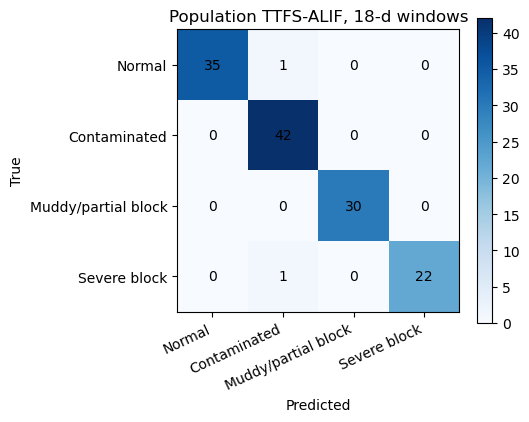

                     precision  recall     f1
Normal                   1.000   0.972  0.986
Contaminated             0.955   1.000  0.977
Muddy/partial block      1.000   1.000  1.000
Severe block             1.000   0.957  0.978


In [16]:
import matplotlib.pyplot as plt
m = res["B_pipeline_random_windows"]["ttfs_pop"][-1]
cm = np.array(m["confusion"]); names = cfg.class_names
fig, ax = plt.subplots(figsize=(5.5, 4.5)); im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4), names, rotation=25, ha="right"); ax.set_yticks(range(4), names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Population TTFS-ALIF, 18-d windows")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center")
fig.colorbar(im); fig.tight_layout(); plt.show()
print(pd.DataFrame(m["per_class"]).T.round(3))